# Task 2.2 - Price prediction

In [67]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
from IPython.display import display

In [68]:
data = pd.read_pickle("clean_data.pkl")

# 1 Nerelevantní data

In [69]:
data = data.drop(columns=["url", "name"])

# 2 Chybějící hodnoty

In [70]:
data["brand"] = data["brand"].cat.add_categories(["Unknown"]).fillna("Unknown")
data["color"] = data["color"].fillna(data["color"].mode()[0])

In [71]:
numeric_columns = ["price", "motor_power_w", "battery_capacity_wh", "range_km", "speed_kmh"]

# Runs later. affects IQR iteration
def fill_missing_numeric_values():
    global data
    data[numeric_columns] = data[numeric_columns].fillna(
        data[numeric_columns].median()
    )

# 3 Odlehlé hodnoty


zbavíme se všech numerických hodnot iterativním odstraněním odléhlých hodnot s `1.5 * IQR`; tím nám zůstanou maximálně věrohodná data

Rows before removing: 334

motor_power_w          500.0
battery_capacity_wh    324.0
range_km                45.0
speed_kmh               15.0
dtype: float64

Rows after removing: 126


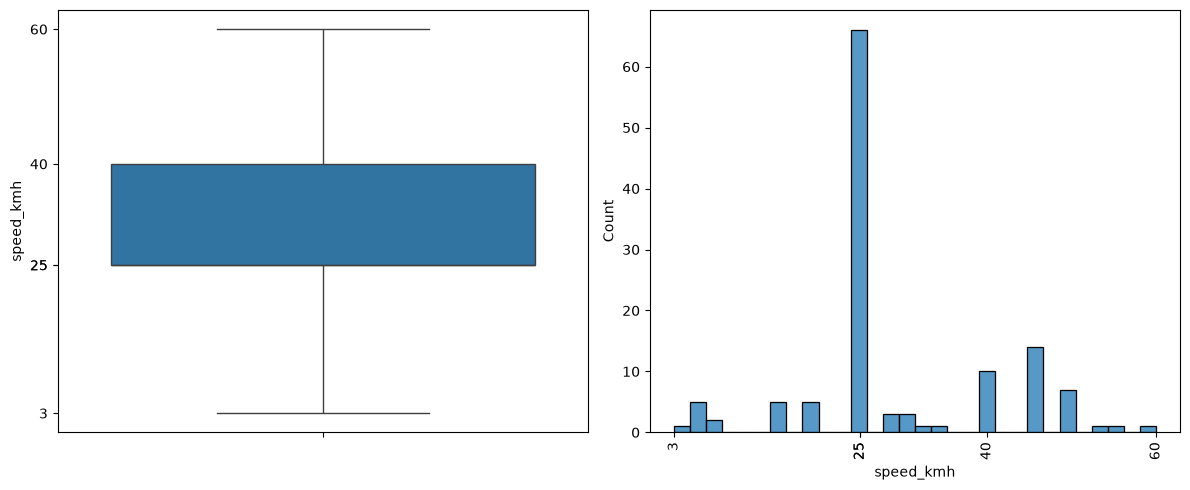

In [72]:
def plot_speed_distribution(data):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    speed = data["speed_kmh"].dropna()

    sns.boxplot(y=speed, ax=axes[0])
    speed_ticks = speed.describe()[["min", "25%", "50%", "75%", "max"]].to_numpy()
    axes[0].set_yticks(speed_ticks)
    axes[0].set_yticklabels([f"{value:,.0f}" for value in speed_ticks])

    sns.histplot(x=speed, bins=30, ax=axes[1])
    axes[1].set_xticks(speed_ticks)
    axes[1].set_xticklabels([f"{value:,.0f}" for value in speed_ticks])
    axes[1].tick_params(axis="x", labelrotation=90)

    fig.tight_layout()
    plt.show()


numeric_columns = ["motor_power_w", "battery_capacity_wh", "range_km", "speed_kmh"]

def get_rid_of_price_outliers():
    global data

    while True:
        q1 = data[numeric_columns].quantile(0.25)
        q3 = data[numeric_columns].quantile(0.75)
        iqr = q3 - q1
        lower_bounds = q1 - 1.5 * iqr
        upper_bounds = q3 + 1.5 * iqr
        within_bounds = (
            data[numeric_columns].notna().all(axis=1)
            & data[numeric_columns].ge(lower_bounds).all(axis=1)
            & data[numeric_columns].le(upper_bounds).all(axis=1)
        )

        filtered_data = data.loc[within_bounds]
        if len(filtered_data) == len(data):
            break
        data = filtered_data

    print(iqr, end="\n\n")


print(f"Rows before removing: {len(data)}", end="\n\n")
get_rid_of_price_outliers()
print(f"Rows after removing: {len(data)}")
plot_speed_distribution(data)

In [73]:
fill_missing_numeric_values()

# 4 'Numerizace' kategorických hodnot

má smysl si zmínit že nemáme ordinální kategorické hodnoty, všechno proto zakódujeme metodou `one hot encoding`

In [74]:
data = pd.get_dummies(data, columns=["brand", "color"], dtype=int)

# 5. Normalizace

nepotřebujeme, nevíme jak bude uživající chtít rozdělit tréňovací a testovací data; normalizace (`Minimax` `Standard N(0,1)` atd.) spolů z tréňovácí částí dat může způsobit `data-leakage`

In [75]:
print(data.info())
display(data.head(5))

<class 'pandas.DataFrame'>
Index: 126 entries, 0 to 328
Data columns (total 94 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price                  126 non-null    float64
 1   motor_power_w          126 non-null    float64
 2   battery_capacity_wh    126 non-null    float64
 3   range_km               126 non-null    float64
 4   speed_kmh              126 non-null    float64
 5   brand_79bike           126 non-null    int64  
 6   brand_a14              126 non-null    int64  
 7   brand_apefox           126 non-null    int64  
 8   brand_ausom            126 non-null    int64  
 9   brand_boyueda          126 non-null    int64  
 10  brand_cunfon           126 non-null    int64  
 11  brand_drvetion         126 non-null    int64  
 12  brand_dt               126 non-null    int64  
 13  brand_duotts           126 non-null    int64  
 14  brand_dyu              126 non-null    int64  
 15  brand_ekxbike         

,price,motor_power_w,battery_capacity_wh,range_km,speed_kmh,brand_79bike,brand_a14,brand_apefox,brand_ausom,brand_boyueda,...,color_pearl white,color_pinkish purple,color_purple,color_red,color_satin black,color_silver,color_silver white,color_white,color_yellow,color_yellow graffiti
0,10656.98,500.0,998.4,90.0,20.0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
7,14298.33,1200.0,1040.0,70.0,25.0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,15754.86,1000.0,998.4,70.0,15.0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12,12113.53,350.0,720.0,30.0,28.0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
18,26678.89,1000.0,816.0,40.0,45.0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [76]:
data.to_csv("price_prediction_data.csv", index=False)
print("Saved price_prediction_data.csv")

Saved price_prediction_data.csv
